# **IMPORT LIBRARIES AND CONFIGURATION**

In [23]:
from pathlib import Path
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)
from sklearn.model_selection import ShuffleSplit

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42

OUTPUT_DIR = Path("/content/clustering_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# **LOAD DATASET**

In [24]:
DATA_PATH = Path("/content/Sales-[5444].csv")

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.astype(str).str.strip()

original_rows = len(df)
original_columns = len(df.columns)
original_missing = int(df.isna().sum().sum())

empty_rows_removed = int(df.isna().all(axis=1).sum())
df = df.dropna(how="all")

duplicate_rows_removed = int(df.duplicated().sum())
data = df.drop_duplicates().reset_index(drop=True)

dataset_summary = pd.DataFrame({
    "Measure": [
        "Original records",
        "Completely empty rows removed",
        "Duplicate rows removed",
        "Final records",
        "Original columns",
        "Missing cells in original data"
    ],
    "Value": [
        original_rows,
        empty_rows_removed,
        duplicate_rows_removed,
        len(data),
        original_columns,
        original_missing
    ]
})

display(dataset_summary)
display(data.head(8))

,Measure,Value
0,Original records,1000
1,Completely empty rows removed,0
2,Duplicate rows removed,0
3,Final records,1000
4,Original columns,10
5,Missing cells in original data,185


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.990,US $84.99/ea,10.000,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,NaN,US $109.99,8.000,8 available / 48 sold,48.000,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.000,US $100.00,10.000,More than 10 available / 27 sold,27.000,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States"
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...,Eau de Toilette,NaN,US $44.99/ea,2.000,2 available / 159 sold,159.000,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States"
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.910,NaN,NaN,Limited quantity available / 156 sold,NaN,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States"
5,Multiple Brands,Men's Perfume Sampler 10pcs Sample Vials Desig...,Perfume,14.990,US $14.99,10.000,More than 10 available / 79 sold,79.000,"May 23, 2024 06:57:41 PDT","Houston, Texas, United States"
6,Maison Alhambra,Glacier Bold by Maison Alhambra 3.4oz EDP for ...,Eau de Parfum,30.990,US $30.99/ea,9.000,9 available / 39 sold,39.000,"May 16, 2024 13:42:49 PDT","Englewood Cliffs, New Jersey, United States"
7,Unbranded,Parfums De-Marly-Haltane Eau de Parfum spray 4...,Eau de Parfum,85.000,US $85.00,NaN,Last One / 6 sold,"7,654.000","May 24, 2024 00:10:39 PDT","Ithaca, New York, United States"


# **DATASET EXPLORATION: Dataset overview and missing values**

,Data Type,Non-Null,Missing,Missing (%),Unique Values
Column,,,,,
Item_Name,object,999,1,0.10%,246
details,object,1000,0,0.00%,966
Catatory,object,997,3,0.30%,63
price,float64,995,5,0.50%,600
priceWithCurrency,object,999,1,0.10%,684
available,float64,889,111,11.10%,89
text,object,997,3,0.30%,758
sold,float64,992,8,0.80%,428
lastUpdated,object,947,53,5.30%,933


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Item_Name,999,246,Giorgio Armani,60,NaN,NaN,NaN,NaN,NaN,NaN,NaN
details,1000,966,YSL Yves Saint Laurent Y Eau de Perfume Spray ...,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Catatory,997,63,Eau de Toilette,444,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,995.000,NaN,NaN,NaN,46.433,35.552,3.000,22.990,35.710,59.000,259.090
priceWithCurrency,999,684,US $29.99/ea,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
available,889.000,NaN,NaN,NaN,20.046,61.548,2.000,5.000,10.000,10.000,842.000
text,997,758,More than 10 available / 16 sold,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sold,992.000,NaN,NaN,NaN,775.247,"3,211.433",1.000,14.000,49.500,324.750,"54,052.000"
lastUpdated,947,933,"May 24, 2024 10:26:59 PDT",4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
itemLocation,1000,276,"Dallas, Texas, United States",126,NaN,NaN,NaN,NaN,NaN,NaN,NaN


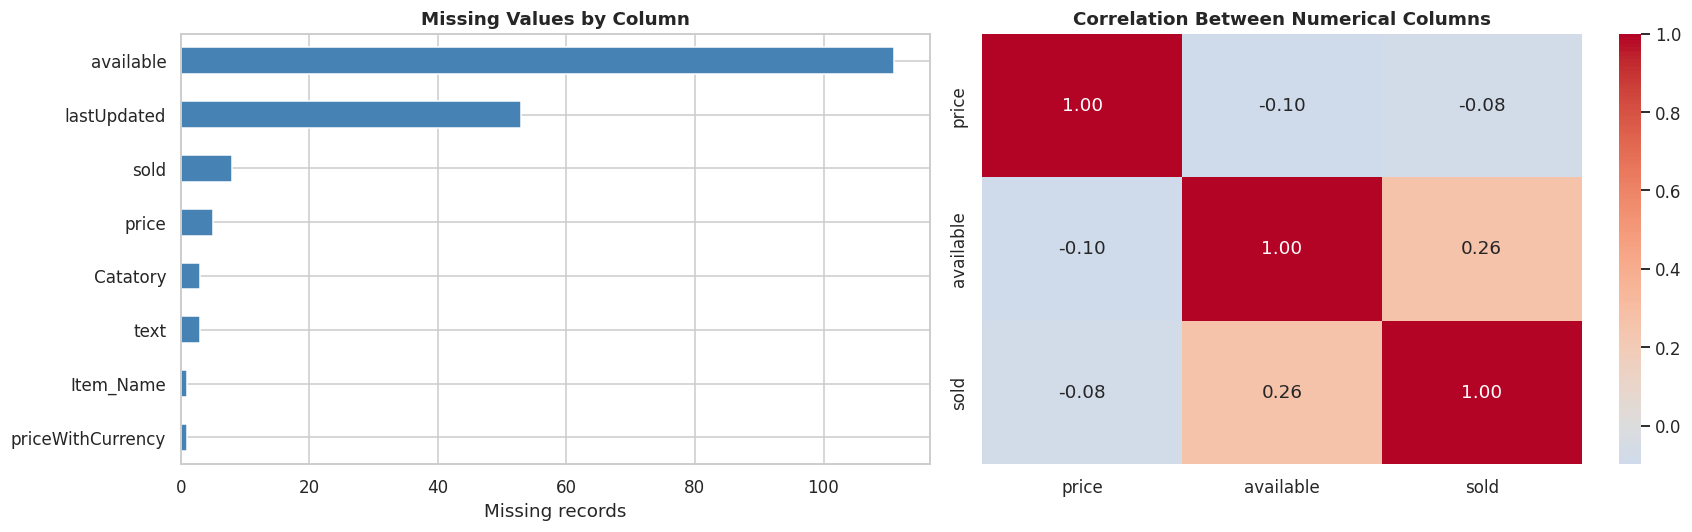

In [25]:
overview = pd.DataFrame({
    "Data Type": data.dtypes.astype(str),
    "Non-Null": data.notna().sum(),
    "Missing": data.isna().sum(),
    "Missing (%)": data.isna().mean() * 100,
    "Unique Values": data.nunique()
}).rename_axis("Column")

display(
    overview.style
    .format({"Missing (%)": "{:.2f}%"})
    .background_gradient(subset=["Missing (%)"], cmap="Oranges")
)

display(data.describe(include="all").T)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

missing = data.isna().sum().sort_values()
missing = missing[missing > 0]

missing.plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Missing Values by Column")
axes[0].set_xlabel("Missing records")
axes[0].set_ylabel("")

numeric_raw = data.select_dtypes(include=np.number)

sns.heatmap(
    numeric_raw.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=axes[1]
)
axes[1].set_title("Correlation Between Numerical Columns")

plt.tight_layout()
plt.show()

# **DATA CLEANING AND QUALITY AUDIT: Clean numerical features and audit data quality**

,Feature,Missing,Unique values
0,Price,5,600
1,Sales,8,428
2,Availability,111,89
3,Category,3,51


,Item_Name,sold,sold_num,text,price_num,Sales Percentile (%)
81,Calvin Klein,"54,052.000","54,052.000","Limited quantity available / 54,052 sold",23.890,100.000
642,Davidoff,"40,130.000","40,130.000","Limited quantity available / 40,130 sold",25.230,99.900
184,Versace,"31,718.000","31,718.000","Limited quantity available / 31,718 sold",39.770,99.800
44,Azzaro,"30,655.000","30,655.000","Limited quantity available / 30,655 sold",46.330,99.700
76,Calvin Klein,"24,048.000","24,048.000","Limited quantity available / 24,048 sold",23.560,99.600
188,Versace,"21,310.000","21,310.000","More than 10 available / 21,310 sold",44.940,99.500
57,Versace,"19,899.000","19,899.000","Limited quantity available / 19,899 sold",36.880,99.400
61,2nd To None,"18,882.000","18,882.000","9 available / 18,882 sold",6.650,99.300
163,Davidoff,"13,549.000","13,549.000","Limited quantity available / 13,549 sold",38.240,99.200
58,Kenneth Cole,"12,865.000","12,865.000","Limited quantity available / 12,865 sold",24.700,99.100


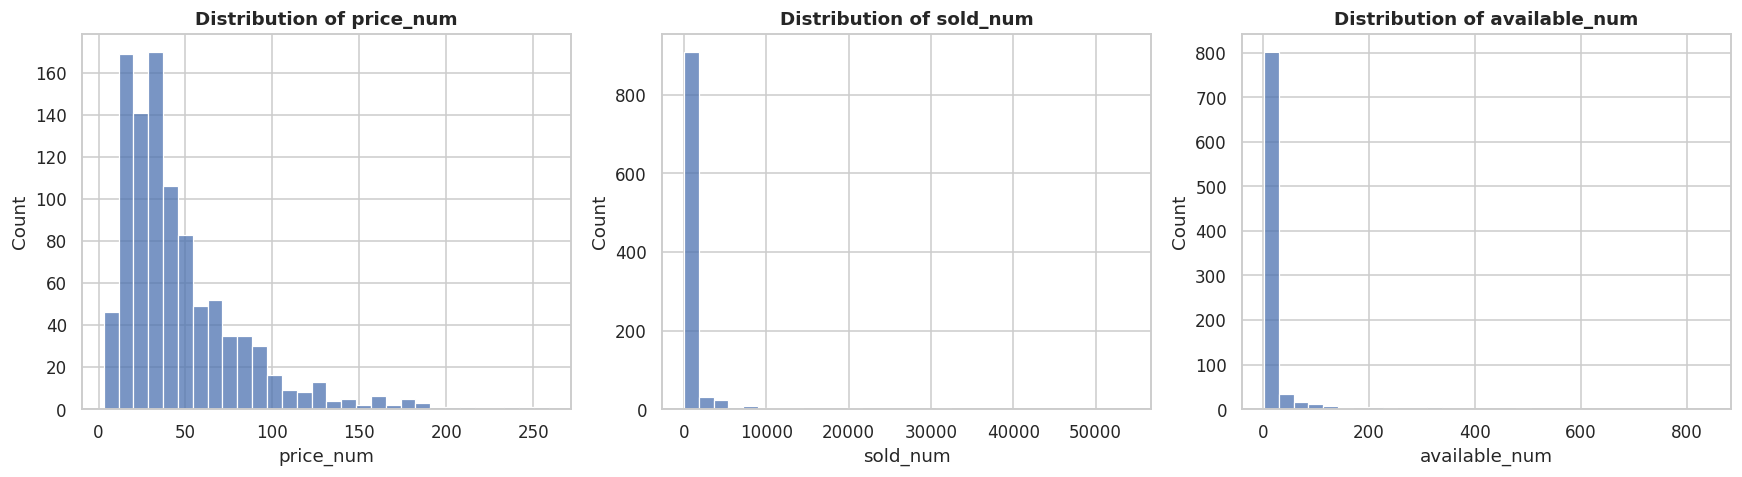

In [26]:
data["price_num"] = pd.to_numeric(
    data["price"].astype("string")
    .str.replace(",", "", regex=False)
    .str.extract(r"(-?\d+(?:\.\d+)?)", expand=False),
    errors="coerce"
)

data["sold_num"] = pd.to_numeric(
    data["sold"].astype("string")
    .str.replace(",", "", regex=False)
    .str.extract(r"(-?\d+(?:\.\d+)?)", expand=False),
    errors="coerce"
)

availability_text = data["available"].astype("string").str.strip()

data["available_num"] = pd.to_numeric(
    availability_text.str.replace(",", "", regex=False)
    .str.extract(r"(-?\d+(?:\.\d+)?)", expand=False),
    errors="coerce"
)

# Ambiguous stock descriptions are not treated as exact quantities
ambiguous_stock = availability_text.str.contains(
    r"more\s+than|limited\s+quantity|contact\s+seller",
    case=False,
    na=False
)

data.loc[ambiguous_stock, "available_num"] = np.nan

# Invalid negative values
data.loc[data["price_num"] < 0, "price_num"] = np.nan
data.loc[data["sold_num"] < 0, "sold_num"] = np.nan
data.loc[data["available_num"] < 0, "available_num"] = np.nan

# Standardise category spelling and case
data["category_clean"] = (
    data["Catatory"].astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({
        "": pd.NA,
        "nan": pd.NA,
        "none": pd.NA,
        "eau de perfume": "eau de parfum"
    })
)

data["price_model"] = np.log1p(data["price_num"])
data["sold_log"] = np.log1p(data["sold_num"])

quality_summary = pd.DataFrame({
    "Feature": ["Price", "Sales", "Availability", "Category"],
    "Missing": [
        data["price_num"].isna().sum(),
        data["sold_num"].isna().sum(),
        data["available_num"].isna().sum(),
        data["category_clean"].isna().sum()
    ],
    "Unique values": [
        data["price_num"].nunique(),
        data["sold_num"].nunique(),
        data["available_num"].nunique(),
        data["category_clean"].nunique()
    ]
})

display(quality_summary)

audit_columns = [
    c for c in ["Item_Name", "sold", "sold_num", "text", "price_num"]
    if c in data.columns
]

sales_audit = data[audit_columns].copy()
sales_audit["Sales Percentile (%)"] = (
    sales_audit["sold_num"].rank(pct=True) * 100
)

sales_audit = sales_audit.sort_values(
    "sold_num", ascending=False
).head(20)

display(sales_audit)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for column, ax in zip(
    ["price_num", "sold_num", "available_num"], axes
):
    sns.histplot(data[column].dropna(), bins=30, ax=ax)
    ax.set_title(f"Distribution of {column}")

plt.tight_layout()
plt.show()

# **PREPROCESSING AND FEATURE ENCODING**

In [28]:
baseline_features = ["price_model", "sold_log"]
availability_features = ["price_model", "sold_log", "available_num"]
categorical_features = ["category_clean"]

# Convert pandas nullable values to standard NumPy-compatible missing values
data["category_clean"] = (
    data["category_clean"]
    .astype(object)
    .where(data["category_clean"].notna(), np.nan)
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

baseline_preprocessor = ColumnTransformer([
    ("numeric", clone(numeric_pipeline), baseline_features)
])

availability_preprocessor = ColumnTransformer([
    ("numeric", clone(numeric_pipeline), availability_features)
])

category_preprocessor = ColumnTransformer([
    ("numeric", clone(numeric_pipeline), baseline_features),
    ("category", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]), categorical_features)
])

X_baseline = np.asarray(
    baseline_preprocessor.fit_transform(data), dtype=float
)

X_availability = np.asarray(
    availability_preprocessor.fit_transform(data), dtype=float
)

X_category = np.asarray(
    category_preprocessor.fit_transform(data), dtype=float
)

preprocessing_summary = pd.DataFrame({
    "Feature Set": [
        "Price + Sales",
        "Price + Sales + Availability",
        "Price + Sales + Category"
    ],
    "Records": [
        X_baseline.shape[0],
        X_availability.shape[0],
        X_category.shape[0]
    ],
    "Encoded Features": [
        X_baseline.shape[1],
        X_availability.shape[1],
        X_category.shape[1]
    ],
    "Missing Values Remaining": [
        np.isnan(X_baseline).sum(),
        np.isnan(X_availability).sum(),
        np.isnan(X_category).sum()
    ]
})

display(preprocessing_summary)

assert np.isfinite(X_baseline).all()
assert np.isfinite(X_availability).all()
assert np.isfinite(X_category).all()

,Feature Set,Records,Encoded Features,Missing Values Remaining
0,Price + Sales,1000,2,0
1,Price + Sales + Availability,1000,3,0
2,Price + Sales + Category,1000,53,0


# **K-MEANS PARAMETER SELECTION**

,Clusters,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,"1,239.10",0.3515,1.1311,612.85
1,3,783.06,0.3776,0.8759,774.72
2,4,625.20,0.3559,0.8931,730.07
3,5,502.35,0.3515,0.9260,741.59
4,6,429.96,0.3516,0.8237,725.94
5,7,369.02,0.3449,0.8505,731.46
6,8,328.81,0.3375,0.8416,720.27


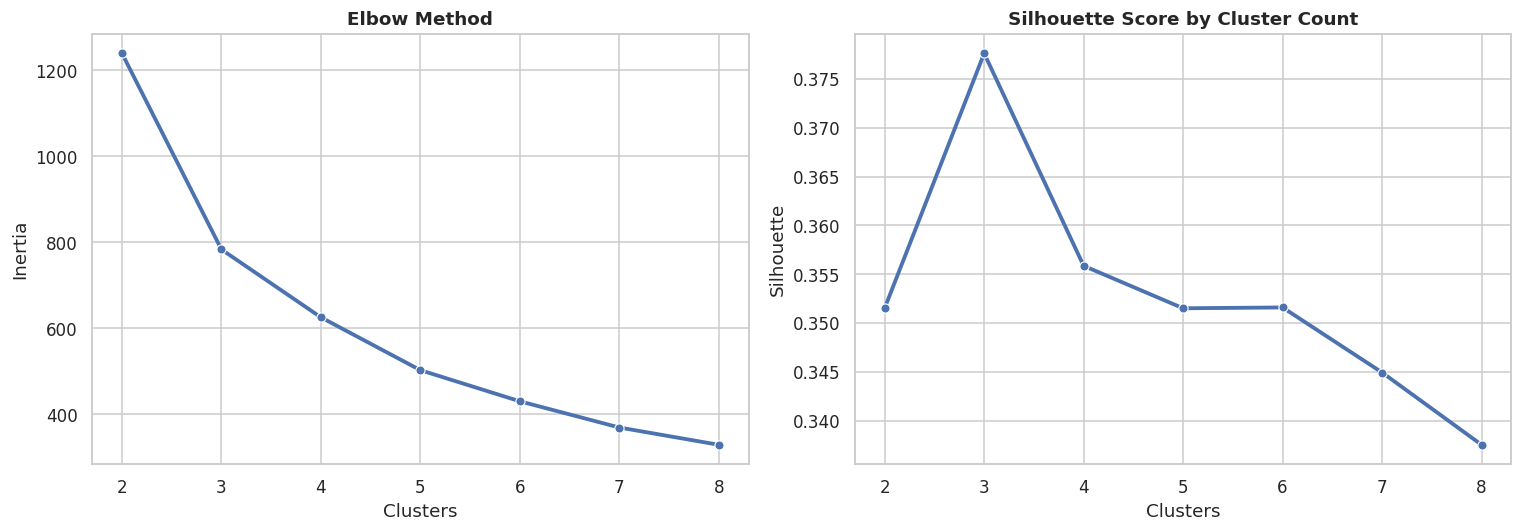

,Selection,Cluster Count
0,Highest-silhouette K-Means candidate,3


In [29]:
k_results = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=20
    )

    labels = model.fit_predict(X_baseline)

    k_results.append({
        "Clusters": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X_baseline, labels),
        "Davies-Bouldin": davies_bouldin_score(X_baseline, labels),
        "Calinski-Harabasz": calinski_harabasz_score(
            X_baseline, labels
        )
    })

k_results = pd.DataFrame(k_results)

display(
    k_results.style.format({
        "Inertia": "{:,.2f}",
        "Silhouette": "{:.4f}",
        "Davies-Bouldin": "{:.4f}",
        "Calinski-Harabasz": "{:,.2f}"
    }).background_gradient(subset=["Silhouette"], cmap="Blues")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(
    data=k_results, x="Clusters", y="Inertia",
    marker="o", linewidth=2.5, ax=axes[0]
)
axes[0].set_title("Elbow Method")
axes[0].set_xticks(range(2, 9))

sns.lineplot(
    data=k_results, x="Clusters", y="Silhouette",
    marker="o", linewidth=2.5, ax=axes[1]
)
axes[1].set_title("Silhouette Score by Cluster Count")
axes[1].set_xticks(range(2, 9))

plt.tight_layout()
plt.show()

best_k = int(
    k_results.loc[k_results["Silhouette"].idxmax(), "Clusters"]
)

display(pd.DataFrame({
    "Selection": ["Highest-silhouette K-Means candidate"],
    "Cluster Count": [best_k]
}))

# **K-MEANS AND HIERARCHICAL CLUSTERING**

In [ ]:
model_labels = {}
models = {}
best_k = 4

candidate_k = sorted(set([3, 4, 5, best_k]))

for k in candidate_k:
    km = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=20
    )

    model_labels[f"K-Means (k={k})"] = km.fit_predict(X_baseline)
    models[f"K-Means (k={k})"] = km

    hierarchical = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    model_labels[f"Hierarchical (k={k})"] = (
        hierarchical.fit_predict(X_baseline)
    )
    models[f"Hierarchical (k={k})"] = hierarchical

model_sizes = pd.DataFrame([
    {
        "Model": name,
        "Number of clusters": len(np.unique(labels)),
        "Smallest cluster": pd.Series(labels).value_counts().min(),
        "Largest cluster": pd.Series(labels).value_counts().max()
    }
    for name, labels in model_labels.items()
]).sort_values("Model").reset_index(drop=True)

display(model_sizes)

,Model,Number of clusters,Smallest cluster,Largest cluster
0,Hierarchical (k=3),3,186,517
1,Hierarchical (k=4),4,186,324
2,Hierarchical (k=5),5,62,324
3,K-Means (k=3),3,308,372
4,K-Means (k=4),4,177,322
5,K-Means (k=5),5,149,286


# **DBSCAN PARAMETER EXPLORATION**

In [31]:
dbscan_results = []

for min_samples in [5, 10, 15]:
    distances, _ = NearestNeighbors(
        n_neighbors=min_samples + 1
    ).fit(X_baseline).kneighbors(X_baseline)

    kth_distances = np.sort(distances[:, -1])

    eps_values = np.unique(
        np.quantile(kth_distances, [0.50, 0.65, 0.80, 0.90, 0.95])
    )

    for eps in eps_values:
        model = DBSCAN(
            eps=float(eps),
            min_samples=min_samples
        )

        labels = model.fit_predict(X_baseline)
        non_noise = labels != -1
        labels_eval = labels[non_noise]
        cluster_count = len(np.unique(labels_eval))

        score = np.nan
        db_index = np.nan

        if cluster_count >= 2 and non_noise.sum() > cluster_count:
            score = silhouette_score(
                X_baseline[non_noise], labels_eval
            )
            db_index = davies_bouldin_score(
                X_baseline[non_noise], labels_eval
            )

        dbscan_results.append({
            "eps": float(eps),
            "min_samples": min_samples,
            "Clusters": cluster_count,
            "Noise (%)": np.mean(labels == -1) * 100,
            "Silhouette (non-noise)": score,
            "Davies-Bouldin (non-noise)": db_index,
            "Labels": labels,
            "Model": model
        })

dbscan_table = pd.DataFrame([
    {key: value for key, value in result.items()
     if key not in ["Labels", "Model"]}
    for result in dbscan_results
])

display(
    dbscan_table.style.format({
        "eps": "{:.4f}",
        "Noise (%)": "{:.1f}%",
        "Silhouette (non-noise)": "{:.4f}",
        "Davies-Bouldin (non-noise)": "{:.4f}"
    }).background_gradient(
        subset=["Silhouette (non-noise)"], cmap="Blues"
    )
)

valid_dbscan = [
    result for result in dbscan_results
    if pd.notna(result["Silhouette (non-noise)"])
]

best_dbscan = max(
    valid_dbscan,
    key=lambda result: result["Silhouette (non-noise)"],
    default=None
)

if best_dbscan is not None:
    model_labels["DBSCAN"] = best_dbscan["Labels"]
    models["DBSCAN"] = best_dbscan["Model"]

display(pd.DataFrame([{
    "Selected DBSCAN candidate": (
        "Valid multi-cluster solution"
        if best_dbscan is not None
        else "No valid multi-cluster solution found"
    ),
    "eps": best_dbscan["eps"] if best_dbscan is not None else np.nan,
    "min_samples": (
        best_dbscan["min_samples"]
        if best_dbscan is not None else np.nan
    )
}]))

,eps,min_samples,Clusters,Noise (%),Silhouette (non-noise),Davies-Bouldin (non-noise)
0,0.1402,5,22,25.0%,-0.0048,0.6188
1,0.1630,5,13,17.2%,-0.1840,0.6358
2,0.2008,5,11,9.7%,-0.1356,0.6351
3,0.2692,5,2,3.9%,0.3142,0.5135
4,0.3381,5,1,2.1%,nan,nan
5,0.1992,10,5,25.2%,-0.1155,0.7538
6,0.2252,10,2,18.1%,0.3534,0.5287
7,0.2922,10,5,7.9%,-0.0165,0.6309
8,0.3701,10,1,2.8%,nan,nan
9,0.4481,10,1,1.6%,nan,nan


,Selected DBSCAN candidate,eps,min_samples
0,Valid multi-cluster solution,0.225,10


# **MODEL EVALUATION**

,Model,Clusters,Noise (%),Metric basis,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means (k=3),3,0.0%,All records,0.3776,0.8759,774.72
1,K-Means (k=4),4,0.0%,All records,0.3559,0.8931,730.07
2,DBSCAN,2,18.1%,Non-noise records only,0.3534,0.5287,66.11
3,K-Means (k=5),5,0.0%,All records,0.3515,0.9260,741.59
4,Hierarchical (k=5),5,0.0%,All records,0.3386,0.8959,654.25
5,Hierarchical (k=4),4,0.0%,All records,0.3305,0.9187,646.64
6,Hierarchical (k=3),3,0.0%,All records,0.3291,0.9703,589.20


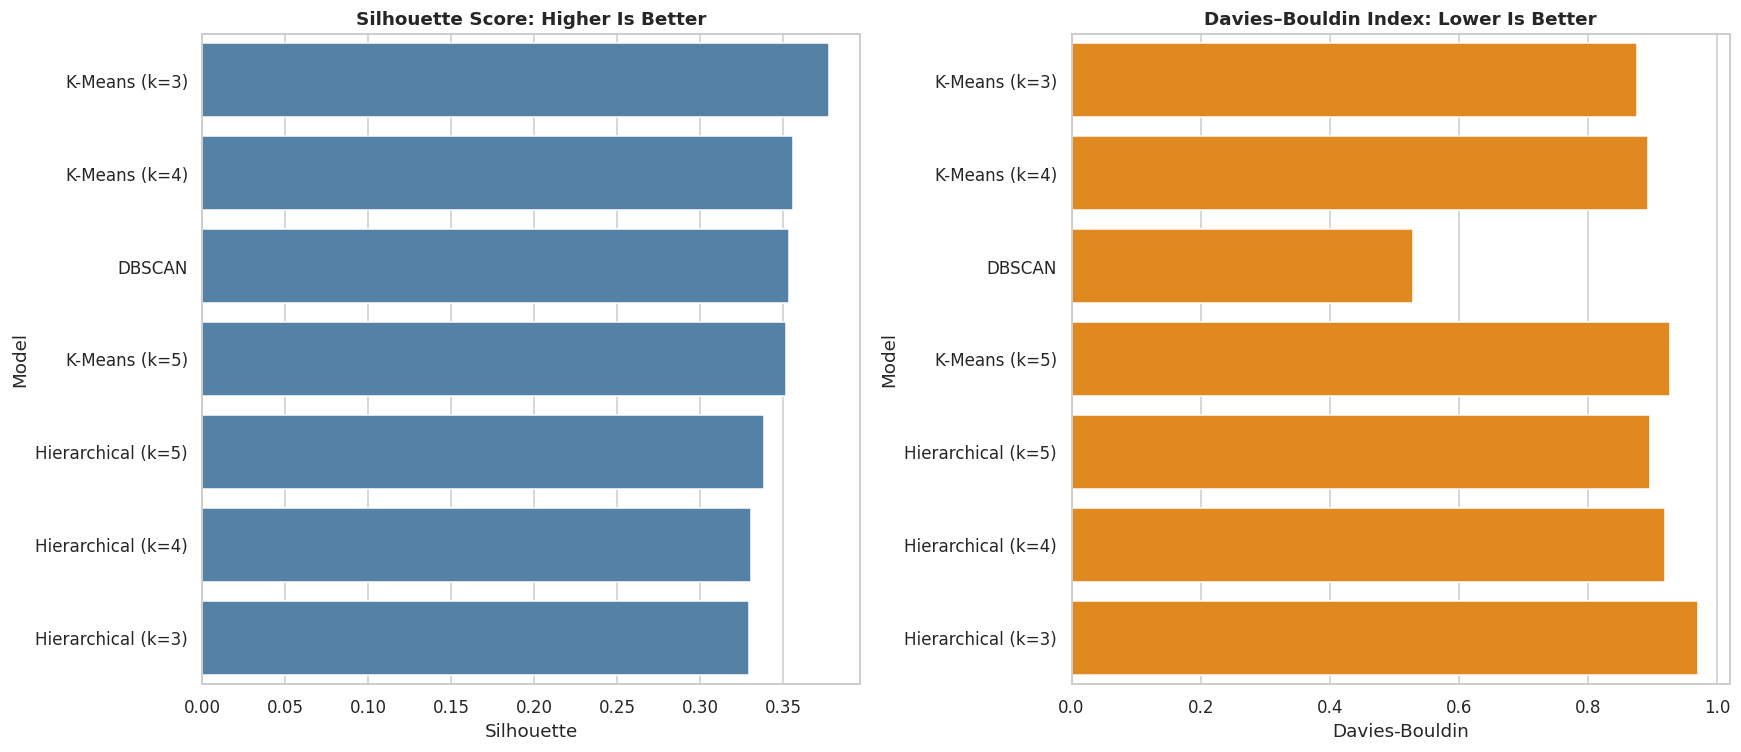

In [32]:
evaluation_rows = []

for name, labels in model_labels.items():
    non_noise = labels != -1
    labels_eval = labels[non_noise]
    X_eval = X_baseline[non_noise]

    n_clusters = len(np.unique(labels_eval))

    result = {
        "Model": name,
        "Clusters": n_clusters,
        "Noise (%)": np.mean(labels == -1) * 100,
        "Metric basis": (
            "Non-noise records only"
            if name == "DBSCAN"
            else "All records"
        ),
        "Silhouette": np.nan,
        "Davies-Bouldin": np.nan,
        "Calinski-Harabasz": np.nan
    }

    if n_clusters >= 2 and len(labels_eval) > n_clusters:
        result["Silhouette"] = silhouette_score(X_eval, labels_eval)
        result["Davies-Bouldin"] = davies_bouldin_score(
            X_eval, labels_eval
        )
        result["Calinski-Harabasz"] = calinski_harabasz_score(
            X_eval, labels_eval
        )

    evaluation_rows.append(result)

evaluation = pd.DataFrame(evaluation_rows).sort_values(
    "Silhouette", ascending=False, na_position="last"
).reset_index(drop=True)

display(
    evaluation.style.format({
        "Noise (%)": "{:.1f}%",
        "Silhouette": "{:.4f}",
        "Davies-Bouldin": "{:.4f}",
        "Calinski-Harabasz": "{:,.2f}"
    }).background_gradient(subset=["Silhouette"], cmap="Greens")
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=evaluation, x="Silhouette", y="Model",
    color="steelblue", ax=axes[0]
)
axes[0].set_title("Silhouette Score: Higher Is Better")

sns.barplot(
    data=evaluation, x="Davies-Bouldin", y="Model",
    color="darkorange", ax=axes[1]
)
axes[1].set_title("Davies–Bouldin Index: Lower Is Better")

plt.tight_layout()
plt.show()

# **FEATURE-SELECTION COMPARISON: Feature-selection sensitivity analysis**

,Feature Set,Clusters,Silhouette,Davies-Bouldin
0,Price + Sales,2,0.3515,1.1311
1,Price + Sales,3,0.3776,0.8759
2,Price + Sales,4,0.3559,0.8931
3,Price + Sales,5,0.3515,0.9260
4,Price + Sales,6,0.3516,0.8237
5,Price + Sales,7,0.3449,0.8505
6,Price + Sales,8,0.3375,0.8416
7,Price + Sales + Availability,2,0.3377,1.2816
8,Price + Sales + Availability,3,0.3333,0.9734
9,Price + Sales + Availability,4,0.3540,0.8352


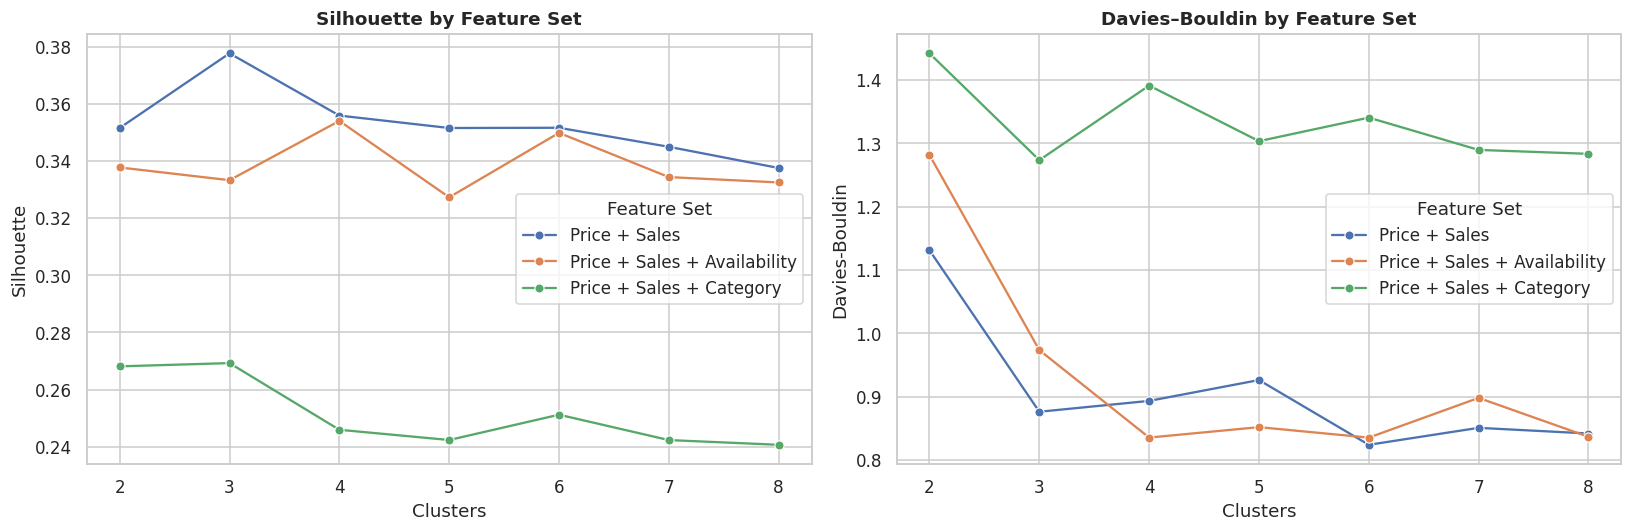

In [33]:
feature_sets = {
    "Price + Sales": X_baseline,
    "Price + Sales + Availability": X_availability,
    "Price + Sales + Category": X_category
}

feature_results = []

for feature_name, X in feature_sets.items():
    for k in range(2, 9):
        labels = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=20
        ).fit_predict(X)

        feature_results.append({
            "Feature Set": feature_name,
            "Clusters": k,
            "Silhouette": silhouette_score(X, labels),
            "Davies-Bouldin": davies_bouldin_score(X, labels)
        })

feature_comparison = pd.DataFrame(feature_results)

display(
    feature_comparison.style.format({
        "Silhouette": "{:.4f}",
        "Davies-Bouldin": "{:.4f}"
    }).background_gradient(subset=["Silhouette"], cmap="Blues")
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(
    data=feature_comparison,
    x="Clusters", y="Silhouette",
    hue="Feature Set", marker="o", ax=axes[0]
)
axes[0].set_title("Silhouette by Feature Set")
axes[0].set_xticks(range(2, 9))

sns.lineplot(
    data=feature_comparison,
    x="Clusters", y="Davies-Bouldin",
    hue="Feature Set", marker="o", ax=axes[1]
)
axes[1].set_title("Davies–Bouldin by Feature Set")
axes[1].set_xticks(range(2, 9))

plt.tight_layout()
plt.show()

# **K-MEANS STABILITY**

In [39]:
N_CLUSTERS = 3

reference_model = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
    n_init=20
)

reference_labels = reference_model.fit_predict(X_baseline)

splitter = ShuffleSplit(
    n_splits=10,
    test_size=0.20,
    random_state=RANDOM_STATE
)

stability_results = []

for run, (train_idx, test_idx) in enumerate(
    splitter.split(X_baseline), start=1
):
    sample_model = KMeans(
        n_clusters=N_CLUSTERS,
        random_state=RANDOM_STATE + run,
        n_init=20
    )

    sample_model.fit(X_baseline[train_idx])

    test_predictions = sample_model.predict(X_baseline[test_idx])

    ari = adjusted_rand_score(
        reference_labels[test_idx],
        test_predictions
    )

    stability_results.append({
        "Run": run,
        "Training Records": len(train_idx),
        "Test Records": len(test_idx),
        "Adjusted Rand Index": ari
    })

stability_df = pd.DataFrame(stability_results)

display(
    stability_df.style.format({
        "Adjusted Rand Index": "{:.4f}"
    }).background_gradient(
        subset=["Adjusted Rand Index"],
        cmap="Greens"
    )
)

stability_summary = pd.DataFrame({
    "Measure": [
        "Mean ARI",
        "Minimum ARI",
        "Maximum ARI",
        "Standard Deviation"
    ],
    "Value": [
        stability_df["Adjusted Rand Index"].mean(),
        stability_df["Adjusted Rand Index"].min(),
        stability_df["Adjusted Rand Index"].max(),
        stability_df["Adjusted Rand Index"].std()
    ]
})

display(stability_summary)

,Run,Training Records,Test Records,Adjusted Rand Index
0,1,800,200,0.9703
1,2,800,200,0.9853
2,3,800,200,1.0000
3,4,800,200,0.9110
4,5,800,200,0.9549
5,6,800,200,0.9840
6,7,800,200,0.9573
7,8,800,200,0.9841
8,9,800,200,0.9855
9,10,800,200,0.9429


,Measure,Value
0,Mean ARI,0.968
1,Minimum ARI,0.911
2,Maximum ARI,1.000
3,Standard Deviation,0.026


# **FINAL MODEL AND PCA**

,Selected Model,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means (k=3),3,0.3776,0.8759,774.72


,Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,57.17%,57.17%
1,PC2,42.83%,100.00%


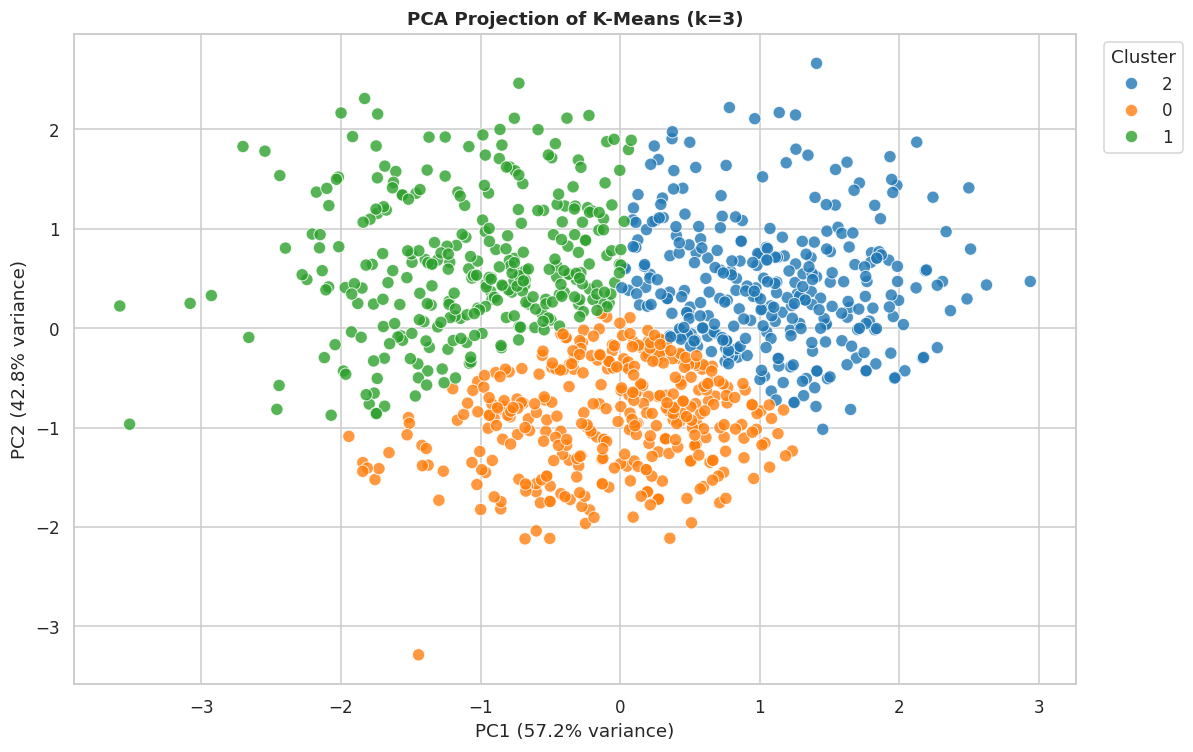

In [40]:
valid_kmeans = evaluation[
    evaluation["Model"].str.startswith("K-Means")
    & evaluation["Silhouette"].notna()
].copy()

final_row = valid_kmeans.sort_values(
    "Silhouette", ascending=False
).iloc[0]

FINAL_MODEL_NAME = final_row["Model"]
FINAL_MODEL = models[FINAL_MODEL_NAME]
FINAL_LABELS = model_labels[FINAL_MODEL_NAME]

data["Cluster"] = FINAL_LABELS

final_summary = pd.DataFrame([{
    "Selected Model": FINAL_MODEL_NAME,
    "Clusters": len(np.unique(FINAL_LABELS)),
    "Silhouette": final_row["Silhouette"],
    "Davies-Bouldin": final_row["Davies-Bouldin"],
    "Calinski-Harabasz": final_row["Calinski-Harabasz"]
}])

display(
    final_summary.style.format({
        "Silhouette": "{:.4f}",
        "Davies-Bouldin": "{:.4f}",
        "Calinski-Harabasz": "{:,.2f}"
    })
)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_baseline)

pca_summary = pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "Explained Variance (%)": pca.explained_variance_ratio_ * 100,
    "Cumulative Variance (%)": (
        np.cumsum(pca.explained_variance_ratio_) * 100
    )
})

display(
    pca_summary.style.format({
        "Explained Variance (%)": "{:.2f}%",
        "Cumulative Variance (%)": "{:.2f}%"
    })
)

pca_plot = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": FINAL_LABELS.astype(str)
})

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=pca_plot,
    x="PC1", y="PC2",
    hue="Cluster",
    palette="tab10",
    s=65,
    alpha=0.8
)

plt.title(f"PCA Projection of {FINAL_MODEL_NAME}")
plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance)"
)
plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance)"
)
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# **CLUSTER BUSINESS PROFILES**

,Cluster,Product_Count,Median_Price,Mean_Price,Median_Sales,Mean_Sales,Median_Availability,Dataset_Share_%
0,0,372,24.99,24.89,19.5,35.9,9.0,37.2%
1,1,308,29.99,33.56,645.5,"2,383.6",10.0,30.8%
2,2,320,74.37,83.61,25.0,68.5,7.0,32.0%


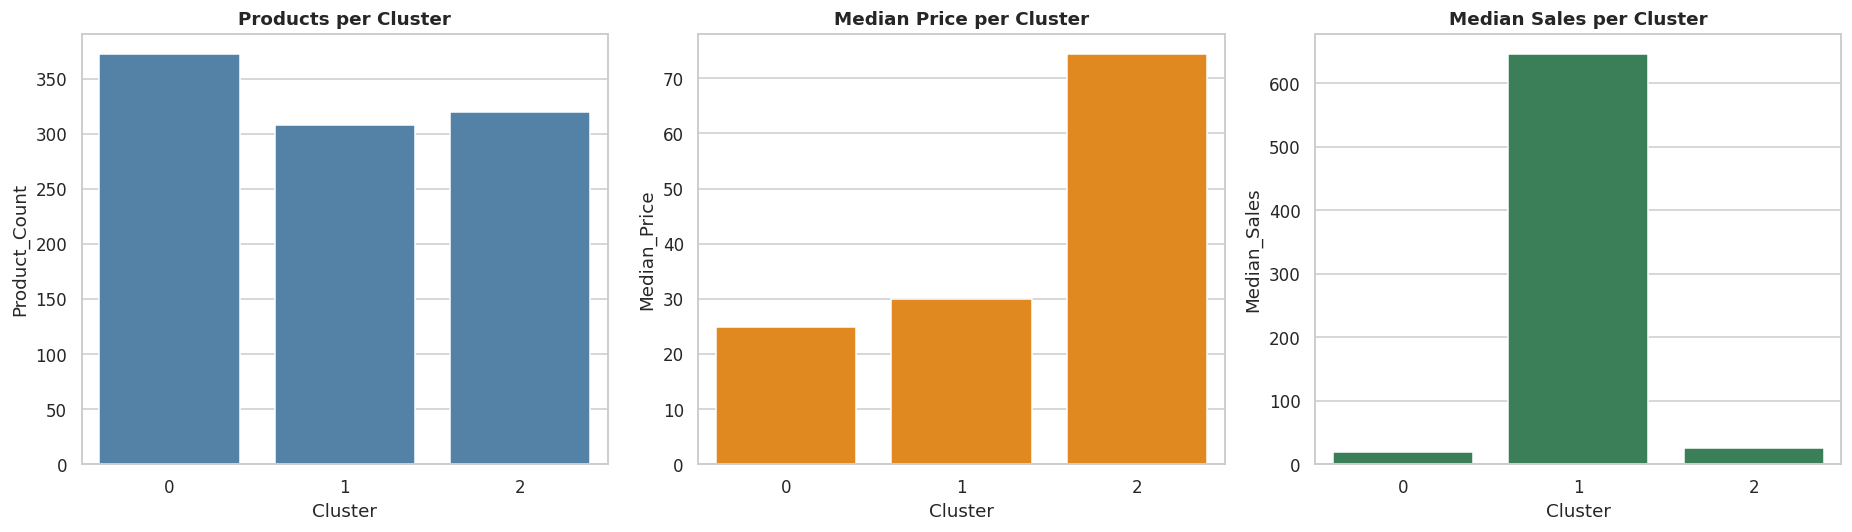

In [41]:
cluster_profile = data.groupby("Cluster").agg(
    Product_Count=("Cluster", "size"),
    Median_Price=("price_num", "median"),
    Mean_Price=("price_num", "mean"),
    Median_Sales=("sold_num", "median"),
    Mean_Sales=("sold_num", "mean"),
    Median_Availability=("available_num", "median")
).reset_index()

cluster_profile["Dataset_Share_%"] = (
    cluster_profile["Product_Count"] / len(data) * 100
)

display(
    cluster_profile.style.format({
        "Median_Price": "{:,.2f}",
        "Mean_Price": "{:,.2f}",
        "Median_Sales": "{:,.1f}",
        "Mean_Sales": "{:,.1f}",
        "Median_Availability": "{:,.1f}",
        "Dataset_Share_%": "{:.1f}%"
    }).background_gradient(
        subset=["Product_Count", "Median_Price", "Median_Sales"],
        cmap="Blues"
    )
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(
    data=cluster_profile, x="Cluster", y="Product_Count",
    color="steelblue", ax=axes[0]
)
axes[0].set_title("Products per Cluster")

sns.barplot(
    data=cluster_profile, x="Cluster", y="Median_Price",
    color="darkorange", ax=axes[1]
)
axes[1].set_title("Median Price per Cluster")

sns.barplot(
    data=cluster_profile, x="Cluster", y="Median_Sales",
    color="seagreen", ax=axes[2]
)
axes[2].set_title("Median Sales per Cluster")

plt.tight_layout()
plt.show()

# **CATEGORY COMPOSITION: Top 10 category composition**

Category_Group,Other categories,body spray,cologne,eau de cologne,eau de parfum,eau de toilette,edt,fragrances,gift sets,parfum,perfume
Cluster,,,,,,,,,,,
0,6.720,0.540,1.080,6.720,29.300,39.780,0.270,6.990,0.540,0.810,7.260
1,3.900,0.650,0.320,7.790,18.180,64.610,0.320,0.320,0.320,1.300,2.270
2,7.190,0.000,0.310,2.500,45.310,33.440,0.620,1.560,0.940,3.120,5.000


,Total Category Share (%)
Cluster,
0,100.000
1,100.000
2,100.000


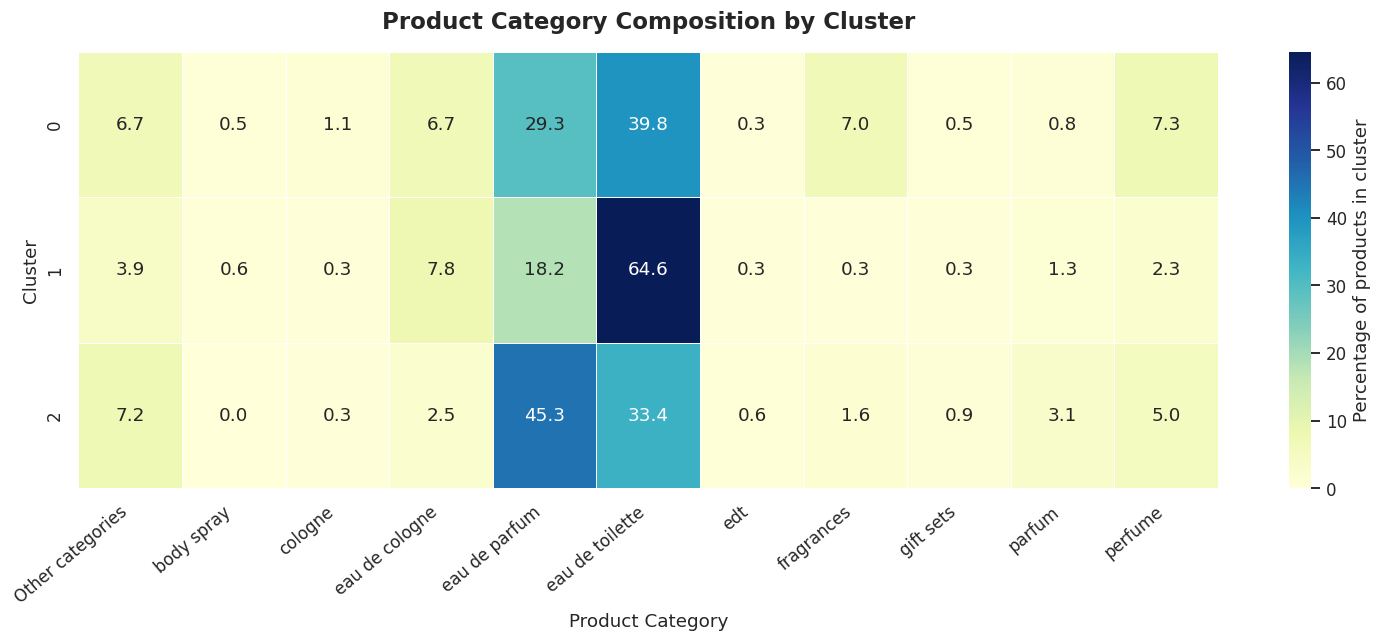

In [44]:
category_data = data[["Cluster", "category_clean"]].copy()

category_data["category_clean"] = (
    category_data["category_clean"].fillna("Unknown")
)

top_categories = (
    category_data["category_clean"]
    .value_counts()
    .head(10)
    .index
)

category_data["Category_Group"] = np.where(
    category_data["category_clean"].isin(top_categories),
    category_data["category_clean"],
    "Other categories"
)

category_share = pd.crosstab(
    category_data["Cluster"],
    category_data["Category_Group"],
    normalize="index"
).mul(100)

# Display the 10 leading categories and the remaining categories
display(category_share.round(2))

# Confirm that each cluster sums to 100%
display(
    category_share.sum(axis=1).rename(
        "Total Category Share (%)"
    ).to_frame()
)

# Visualisation
plt.figure(figsize=(14, 6))

sns.heatmap(
    category_share,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    vmin=0,
    cbar_kws={"label": "Percentage of products in cluster"}
)

plt.title("Product Category Composition by Cluster", fontsize=15, pad=15)
plt.xlabel("Product Category")
plt.ylabel("Cluster")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

# **BUSINESS INTERPRETATION**

In [45]:
overall_median_price = data["price_num"].median()
overall_median_sales = data["sold_num"].median()

business_insights = cluster_profile.copy()

business_insights["Price Position"] = np.where(
    business_insights["Median_Price"] > overall_median_price,
    "Above overall median",
    "At or below overall median"
)

business_insights["Sales Position"] = np.where(
    business_insights["Median_Sales"] > overall_median_sales,
    "Above overall median",
    "At or below overall median"
)

conditions = [
    (business_insights["Median_Price"] > overall_median_price)
    & (business_insights["Median_Sales"] > overall_median_sales),

    (business_insights["Median_Price"] > overall_median_price)
    & (business_insights["Median_Sales"] <= overall_median_sales),

    (business_insights["Median_Price"] <= overall_median_price)
    & (business_insights["Median_Sales"] > overall_median_sales)
]

business_insights["Preliminary Interpretation"] = np.select(
    conditions,
    [
        "Higher-priced listings with higher observed sales",
        "Higher-priced listings with lower observed sales",
        "Lower-priced listings with higher observed sales"
    ],
    default="Lower-priced listings with lower observed sales"
)

display(
    business_insights[[
        "Cluster",
        "Product_Count",
        "Dataset_Share_%",
        "Median_Price",
        "Median_Sales",
        "Price Position",
        "Sales Position",
        "Preliminary Interpretation"
    ]].style.format({
        "Dataset_Share_%": "{:.1f}%",
        "Median_Price": "{:,.2f}",
        "Median_Sales": "{:,.1f}"
    })
)

,Cluster,Product_Count,Dataset_Share_%,Median_Price,Median_Sales,Price Position,Sales Position,Preliminary Interpretation
0,0,372,37.2%,24.99,19.5,At or below overall median,At or below overall median,Lower-priced listings with lower observed sales
1,1,308,30.8%,29.99,645.5,At or below overall median,Above overall median,Lower-priced listings with higher observed sales
2,2,320,32.0%,74.37,25.0,Above overall median,At or below overall median,Higher-priced listings with lower observed sales
